In [ ]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, shock_analysis
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


In [ ]:
# Define GARCH Scaling Function
from arch import arch_model

def garch_scale(series):

    series = series.dropna()

    model = arch_model(
        series,
        mean="Constant",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal"
    )

    res = model.fit(disp="off")

    sigma = pd.Series(
        res.conditional_volatility,
        index=series.index
    )

    return sigma, res

### Import target series and detrend series with HP filter + GARCH SCALING

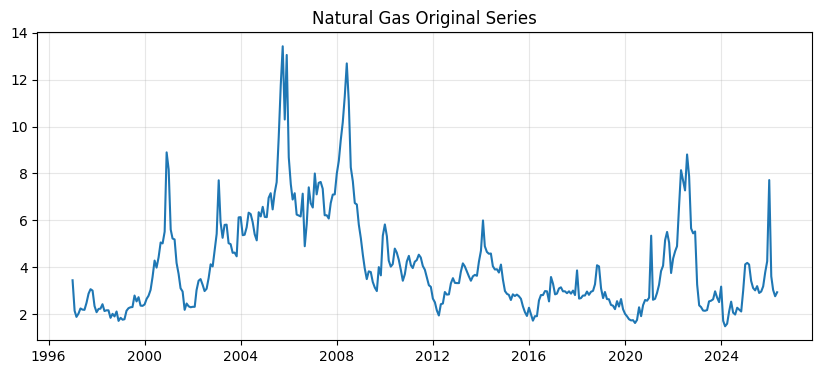

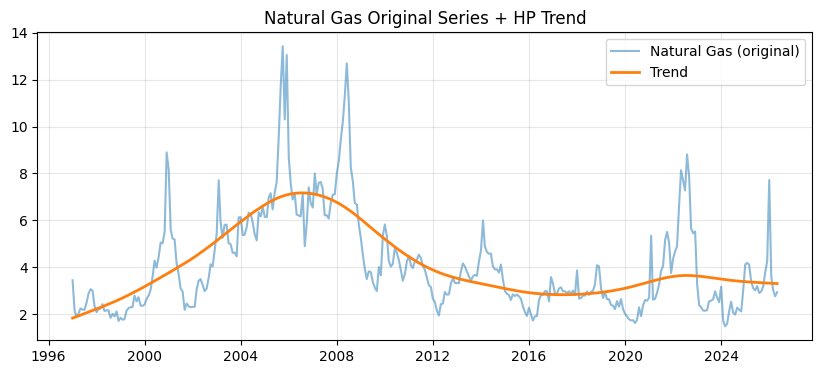

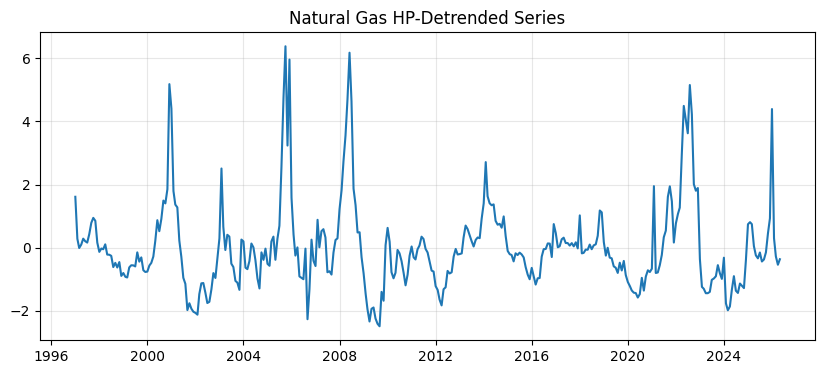

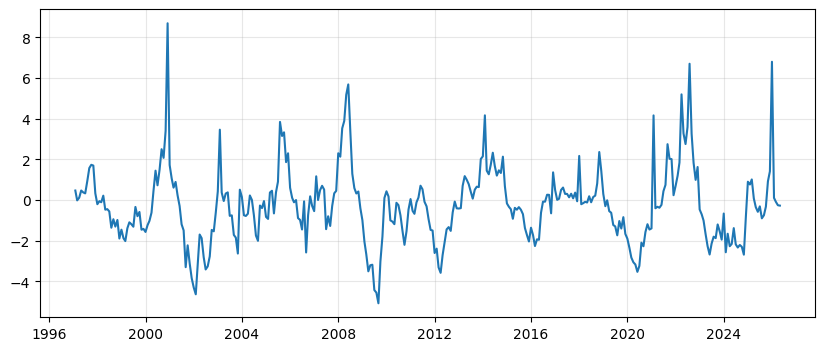

In [3]:
# -------------------------
# DATA
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter
cycle, trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

df_ngas["gas_cycle"] = cycle
df_ngas["gas_trend"] = trend


gas_diff = (df_ngas["gas_cycle"]).diff().dropna()
gas_sigma, gas_garch = garch_scale(gas_diff)


df_ngas["gas_scaled_cycle"]= df_ngas["gas_cycle"]/gas_sigma

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"])
plt.title("Natural Gas Original Series")
plt.grid(alpha=0.3)
plt.show()


# Plot trend decomposition
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["MHHNGSP"], label="Natural Gas (original)", alpha=0.5)
plt.plot(df_ngas.index, df_ngas["gas_trend"], label="Trend", linewidth=2)
plt.title("Natural Gas Original Series + HP Trend")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_cycle"])
plt.title("Natural Gas HP-Detrended Series")
plt.grid(True, alpha=0.3)
plt.show()

# Plot cycle 
plt.figure(figsize=(10,4))
plt.plot(df_ngas.index, df_ngas["gas_scaled_cycle"])
plt.grid(True, alpha=0.3)
plt.show()



### Extract Data for Exogeous Variables

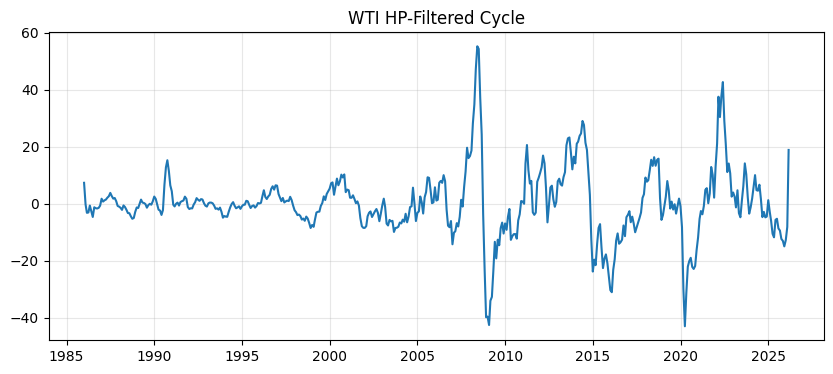

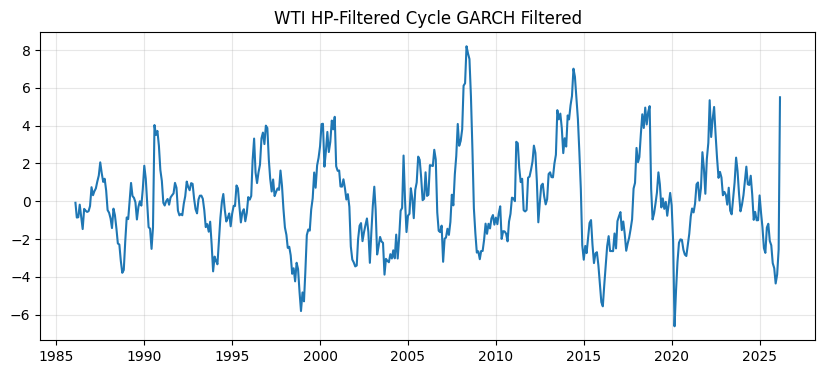

In [4]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter
wti_cycle, wti_trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

wti_diff = (wti_cycle).diff().dropna()
wti_sigma, wti_garch = garch_scale(wti_diff)

wti = wti_cycle/wti_sigma


plt.figure(figsize=(10,4))
plt.plot(wti_cycle)
plt.title("WTI HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(wti)
plt.title("WTI HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

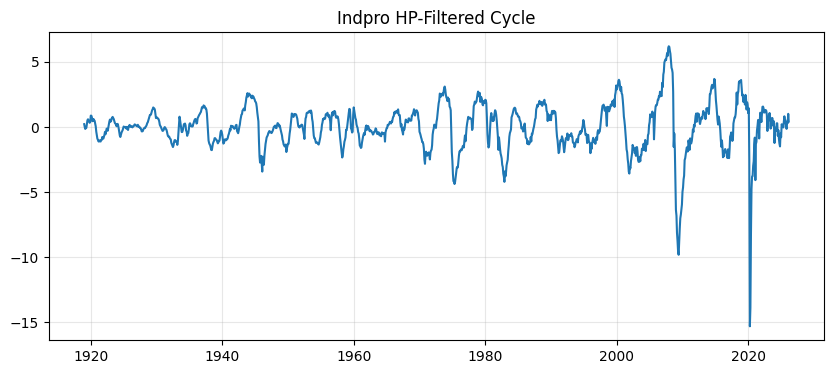

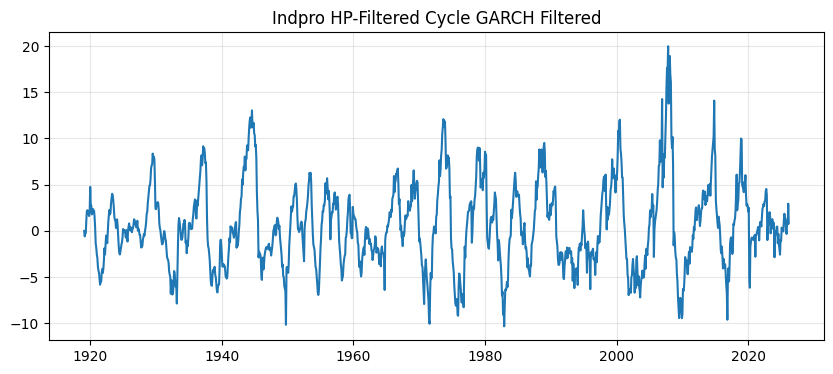

In [6]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter 
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma, indpro_garch = garch_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

/Users/inescastro/.local/lib/python3.12/site-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 1.273e+04. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


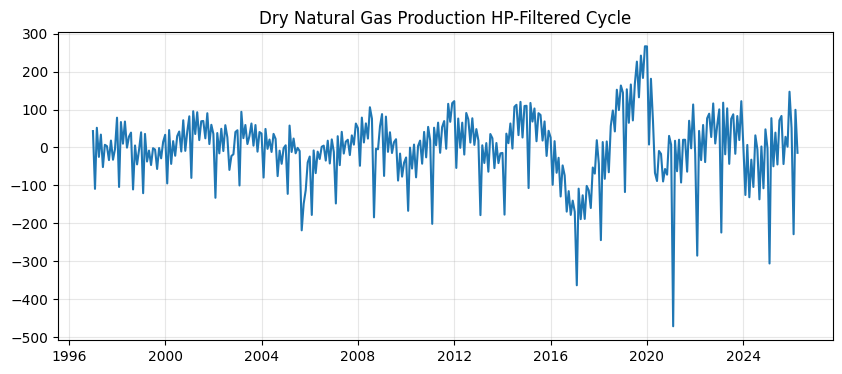

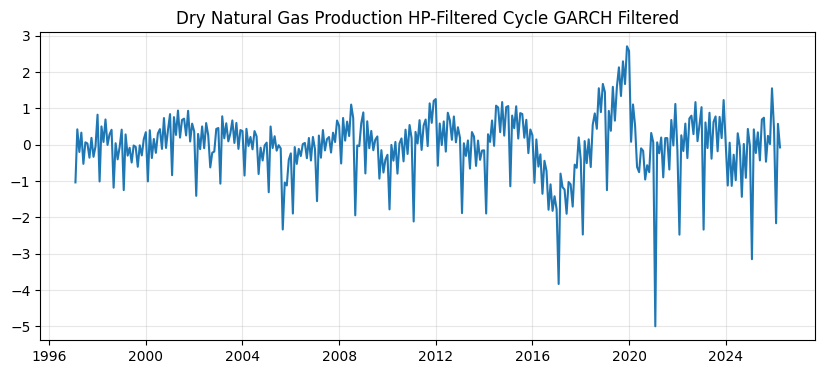

In [8]:
# -------------------------
# Dry Natural Gas Production
# -------------------------

df_ngas_prod = pd.read_excel(
    "Dry NGas Production.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column (e.g., Jan-1997)
df_ngas_prod["Date"] = pd.to_datetime(
    df_ngas_prod["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_prod["Date"] = df_ngas_prod["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_prod = df_ngas_prod.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_ngas_prod=0.001*df_ngas_prod
ngas_prod_cycle, trend = hpfilter(
    df_ngas_prod["U.S. Dry Natural Gas Production (MMcf)"],
    lamb=129600
)


ngas_prod_diff = (ngas_prod_cycle).diff().dropna()
ngas_prod_sigma, ngas_prod_garch = garch_scale(ngas_prod_diff)

ngas_prod = ngas_prod_cycle/ngas_prod_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_prod_cycle)
plt.title("Dry Natural Gas Production HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas_prod)
plt.title("Dry Natural Gas Production HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

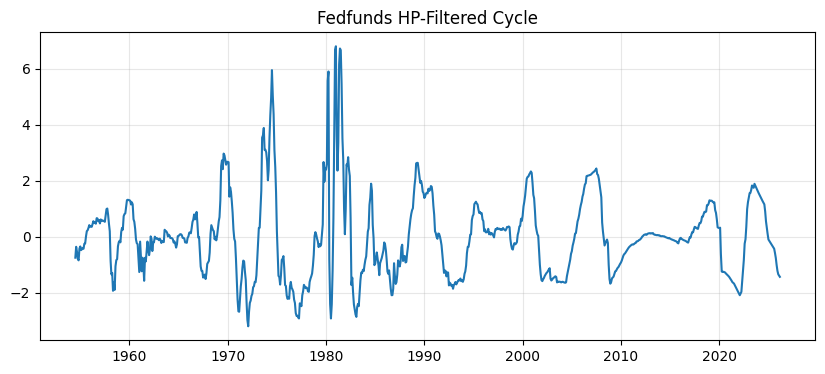

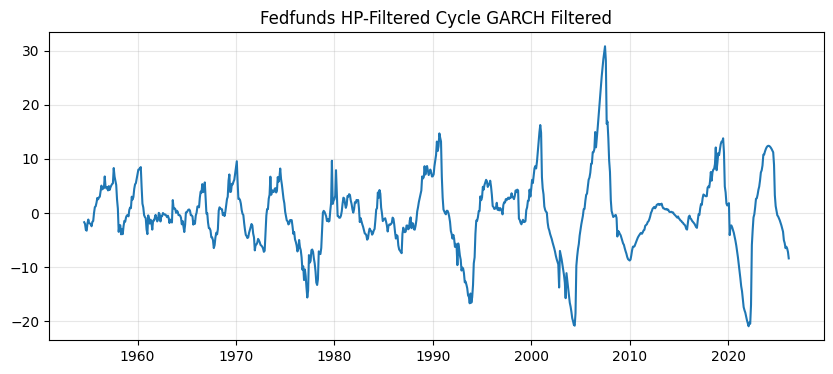

In [9]:
# -------------------------
# Fed Funds
# -------------------------
fedfunds_original = pd.read_csv("FEDFUNDS.csv", parse_dates=["observation_date"])
fedfunds_original = fedfunds_original.dropna().set_index("observation_date")

# -------------------------
# HP Filter 
# -------------------------
fedfunds_cycle, trend = hpfilter(fedfunds_original, lamb=129600)


fedfunds_diff = (fedfunds_cycle).diff().dropna()
fedfunds_sigma, fedfunds_garch = garch_scale(fedfunds_diff)

fedfunds = fedfunds_cycle/fedfunds_sigma


plt.figure(figsize=(10,4))
plt.plot(fedfunds_cycle)
plt.title("Fedfunds HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(fedfunds)
plt.title("Fedfunds HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_17042/1054662910.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


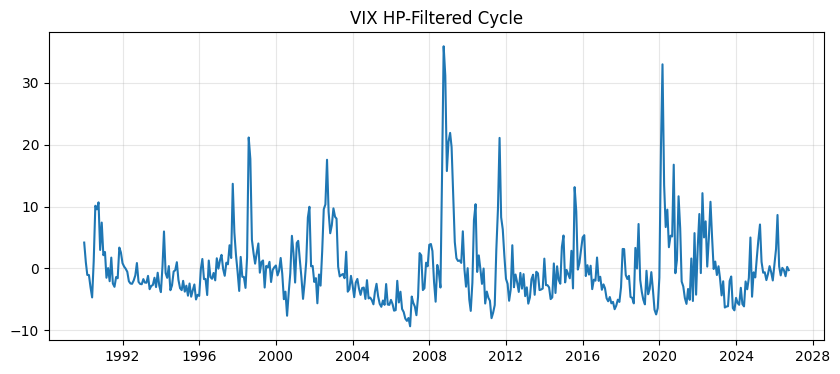

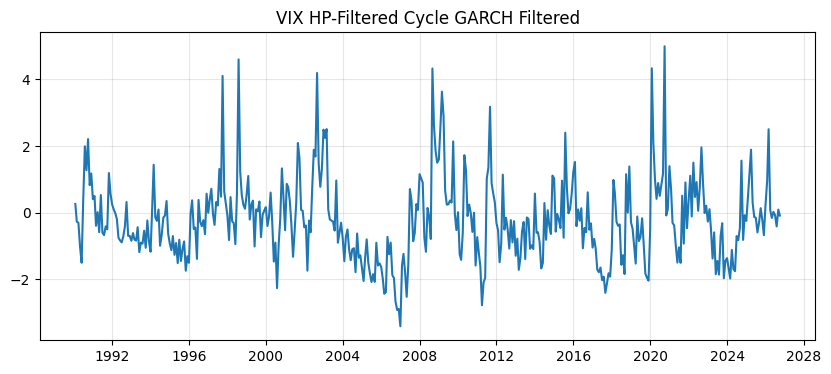

In [10]:
# -------------------------
# VIX
# -------------------------
vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
vix_original = vix_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
vix_cycle, trend = hpfilter(vix_original, lamb=129600)

vix_diff = (vix_cycle).diff().dropna()
vix_sigma, vix_garch = garch_scale(vix_diff)

vix= vix_cycle/vix_sigma


plt.figure(figsize=(10,4))
plt.plot(vix_cycle)
plt.title("VIX HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(vix)
plt.title("VIX HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

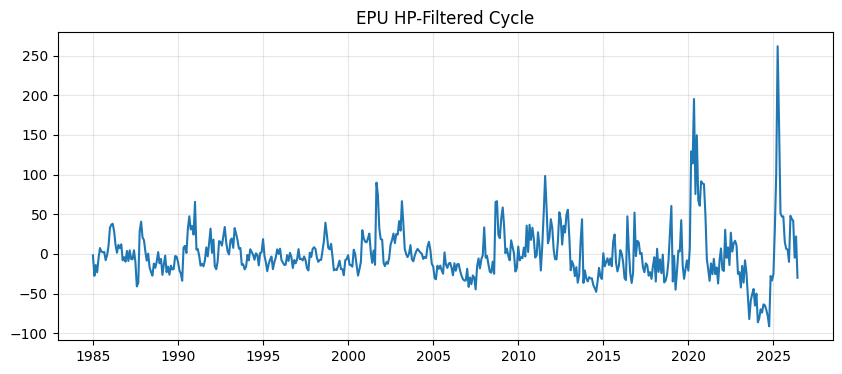

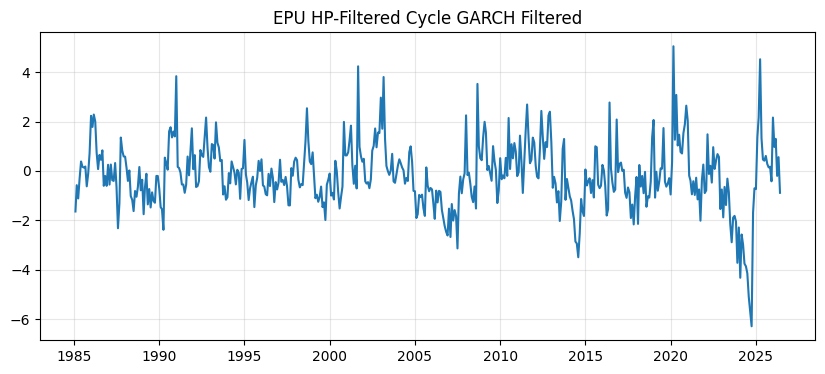

In [12]:
# -------------------------
# Economic Policy Uncertainty US
# -------------------------
df_epu = pd.read_csv("USEPUINDXM.csv", parse_dates=["observation_date"])
df_epu = df_epu.dropna().set_index("observation_date")


# HP filter
epu_cycle , trend = hpfilter(df_epu["USEPUINDXM"], lamb=129600)

epu_diff = (epu_cycle).diff().dropna()
epu_sigma, epu_garch = garch_scale(epu_diff)

epu= epu_cycle/epu_sigma


plt.figure(figsize=(10,4))
plt.plot(epu_cycle)
plt.title("EPU HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(epu)
plt.title("EPU HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

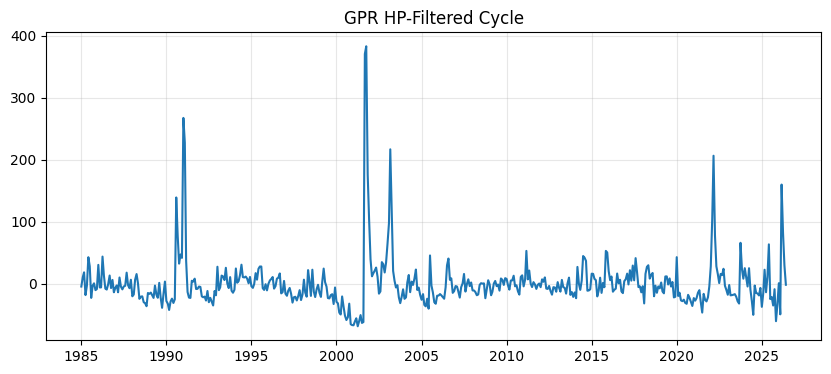

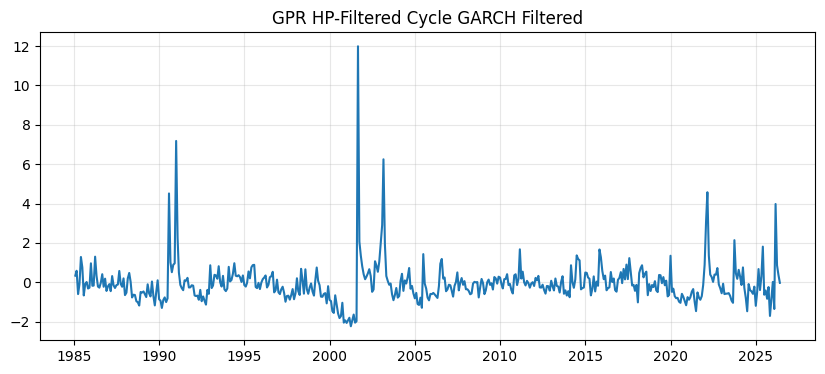

In [13]:
# -------------------------
# GPR
# -------------------------
df = pd.read_excel("GPR.xls", usecols=["month", "GPR"])

# Convert Month column to datetime
df["month"] = pd.to_datetime(df["month"])

# Set Month as index
df = df.set_index("month")

# Extract GPR series
gpr_original = df["GPR"].dropna()

# -------------------------
# HP Filter
# -------------------------
gpr_cycle, gpr_trend = hpfilter(gpr_original, lamb=129600)

gpr_diff = (gpr_cycle).diff().dropna()
gpr_sigma, gpr_garch = garch_scale(gpr_diff)

gpr = gpr_cycle/gpr_sigma


plt.figure(figsize=(10,4))
plt.plot(gpr_cycle)
plt.title("GPR HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(gpr)
plt.title("GPR HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

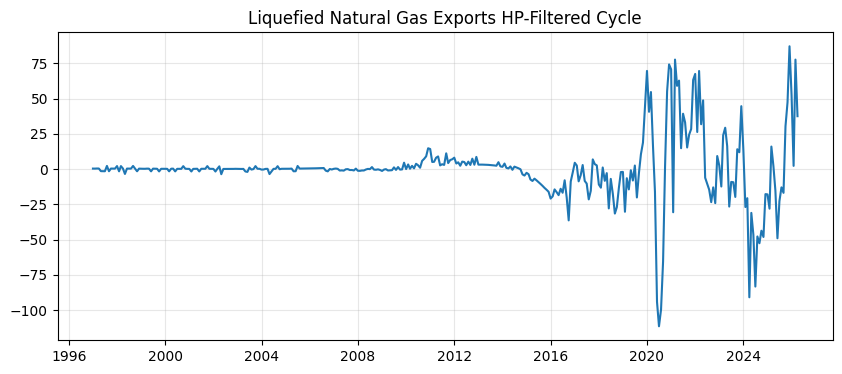

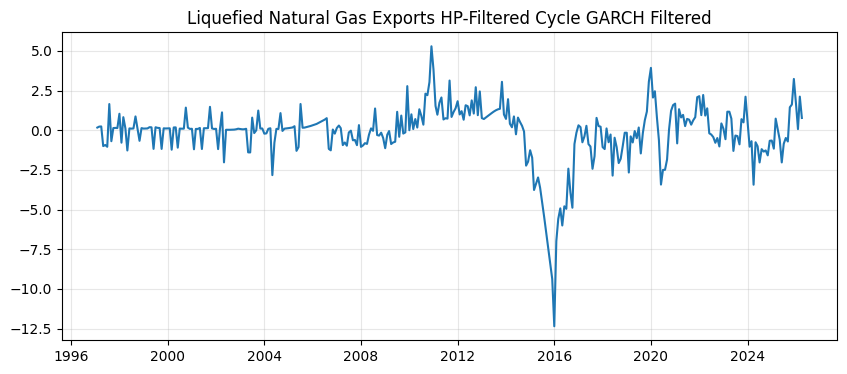

In [14]:
# -------------------------
# LNGas Exports
# -------------------------

df_ngas_exports = pd.read_excel(
    "LNG Exports.xls",
    sheet_name="Data 1",
    skiprows=2
)

# Convert the Date column
df_ngas_exports["Date"] = pd.to_datetime(
    df_ngas_exports["Date"],
    format="%b-%Y"
)

# Set day to 1 for every date
df_ngas_exports["Date"] = df_ngas_exports["Date"].dt.to_period("M").dt.to_timestamp()

# Set Date as index and remove missing values
df_ngas_exports = df_ngas_exports.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_ngas_exports=0.001*df_ngas_exports
ngas_exports_cycle, trend = hpfilter(
    df_ngas_exports["Liquefied U.S. Natural Gas Exports (MMcf)"],
    lamb=129600
)

ngas_exports_diff = (ngas_exports_cycle).diff().dropna()
ngas_exports_sigma, ngas_exports_garch = garch_scale(ngas_exports_diff)

ngas_exports = ngas_exports_cycle/ngas_exports_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_exports_cycle)
plt.title("Liquefied Natural Gas Exports HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas_exports)
plt.title("Liquefied Natural Gas Exports HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

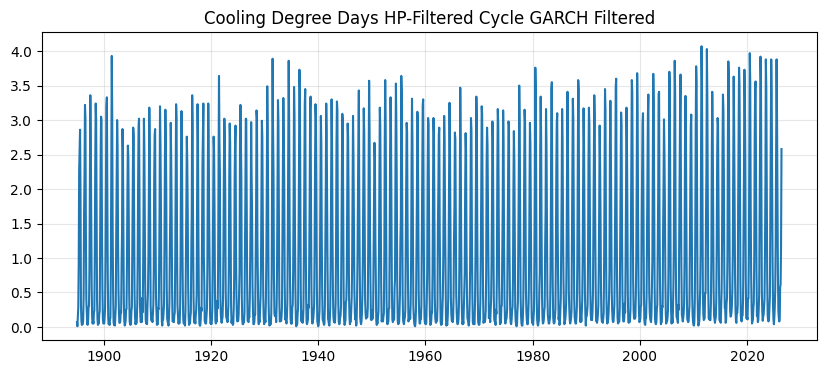

In [15]:
# -------------------------
# Cooling Degree Days
# -------------------------
df_cdd = pd.read_csv(
    "CDD.csv",
    skiprows=2,
    parse_dates=["Date"],
    date_format="%Y%m"
)

df_cdd = df_cdd.set_index("Date").dropna()

# HP filter
cdd=0.01*df_cdd


plt.figure(figsize=(10,4))
plt.plot(cdd)
plt.title("Cooling Degree Days HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

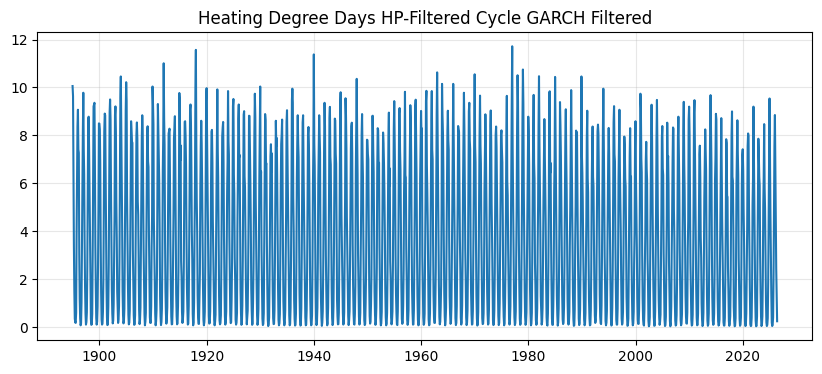

In [16]:
# -------------------------
# Heating Degree Days
# -------------------------
df_hdd = pd.read_csv(
    "HDD.csv",
    skiprows=2,
    parse_dates=["Date"],
    date_format="%Y%m"
)

df_hdd = df_hdd.set_index("Date").dropna()

# HP filter
hdd=0.01*df_hdd

plt.figure(figsize=(10,4))
plt.plot(hdd)
plt.title("Heating Degree Days HP-Filtered Cycle GARCH Filtered")
plt.grid(alpha=0.3)
plt.show()

In [18]:
# Data and Parameters 
df = pd.concat(
    [
        df_ngas["gas_scaled_cycle"], wti, indpro, ngas_prod, fedfunds, vix, epu, gpr, ngas_exports, hdd, cdd
    ],
    axis=1
).dropna()

df.columns = ["gas_scaled_cycle",  "wti", "indpro", "ngas_prod", "fedfunds", "vix", "epu", "gpr", "ngas_exports", "hdd", "cdd"]
df = df.sort_index()

start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["gas_scaled_cycle"].values
X = df[["wti", "indpro", "ngas_prod", "fedfunds", "vix", "epu", "gpr", "ngas_exports", "hdd", "cdd"]].values

var = ["wti","indpro", "ngas_prod", "fedfunds", "vix", "epu", "gpr", "ngas_exports", "hdd", "cdd"]

t0=len(y)-3 # point to calculate predictive density

print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

#Define Grid for all experiments
grid_min=-50
grid_max=50
ngrid=3000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)


#Parameters for effect of exogenous regressors on bimodality 
std=3
values=30

prominence = 0.01

y_limits=(-10, 10)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


In [ ]:
#Import PSY Pickle

with open("psy_ngas.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -470.37918821210405

Estimated parameters:
phi             =     0.0549 (0.0398)
psi             =     0.8424 (0.0261)
sigma           =     0.4043 (0.0290)

Hessian condition number:
3.1093267410817824

Eigenvalues of Hessian:
[ 581.87368247 1809.23540084 1198.54983343]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -470.379188
AIC:            946.758376
BIC:            958.314984
R^2:            0.617527

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 14.839076, p-value = 0.000117084
    lag  5: statistic = 19.738828, p-value = 0.00139888
    lag 10: statistic = 25.632651, p-value = 0.00426696
    lag 20: statistic = 29.445811, p-value = 0.079345

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 27.709053, p-value = 1.41001e-07
    lag  5: 

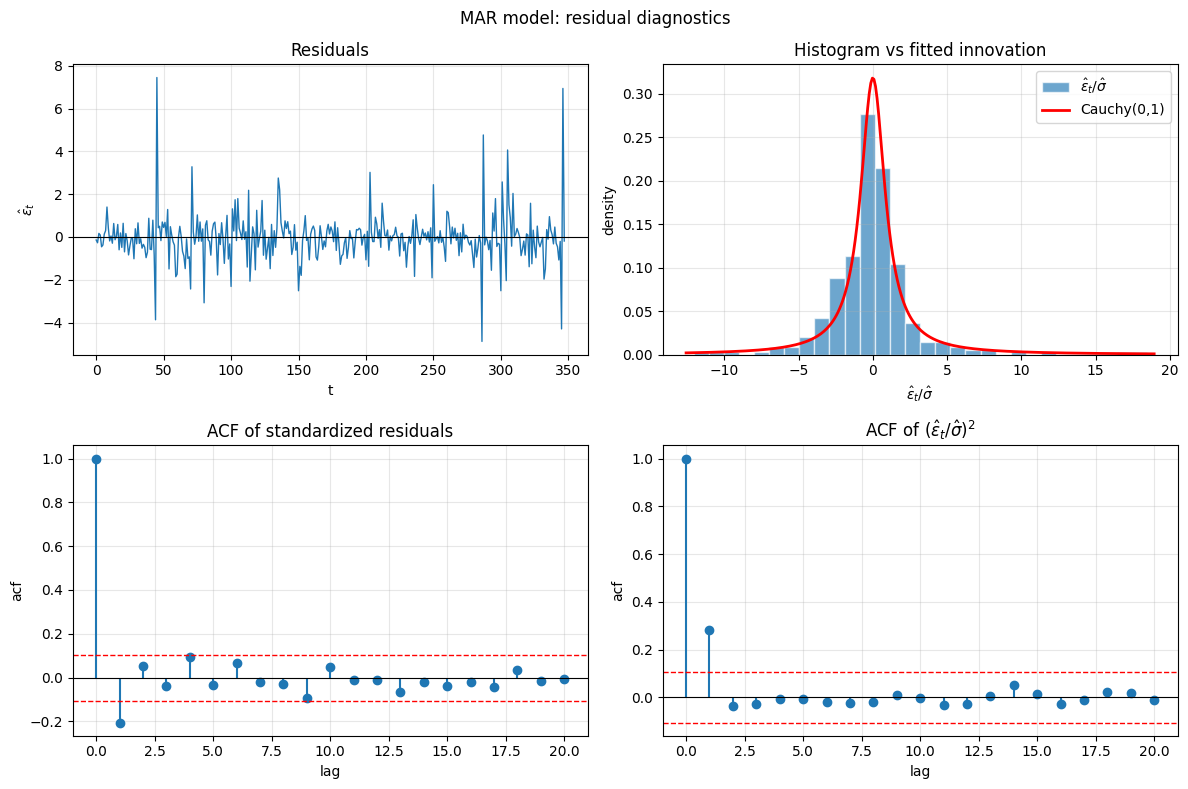

In [20]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

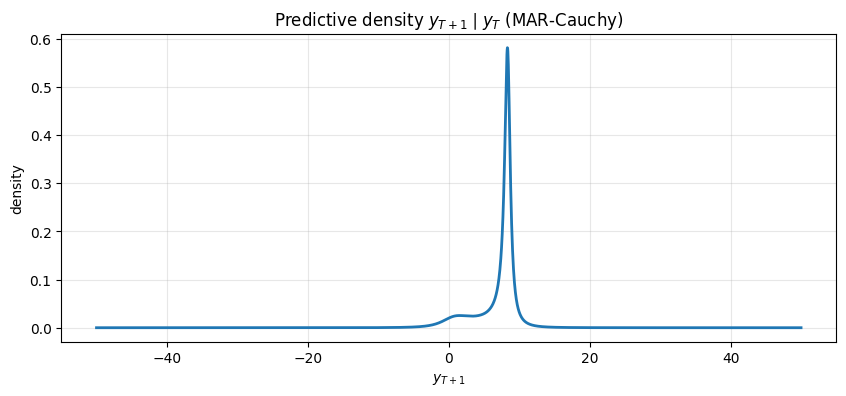

In [21]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

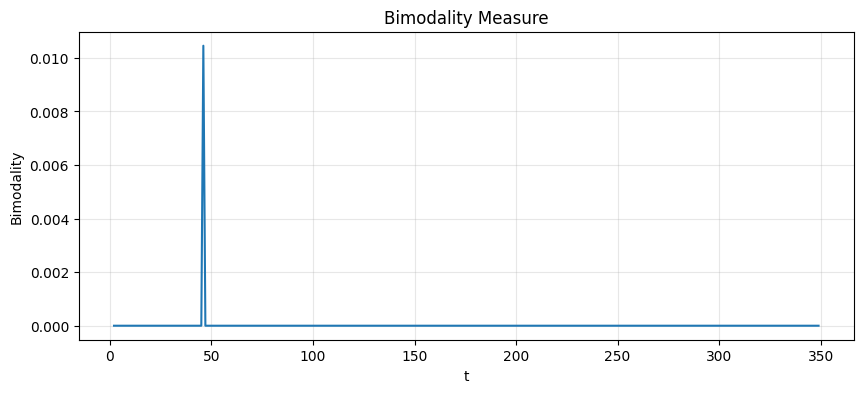

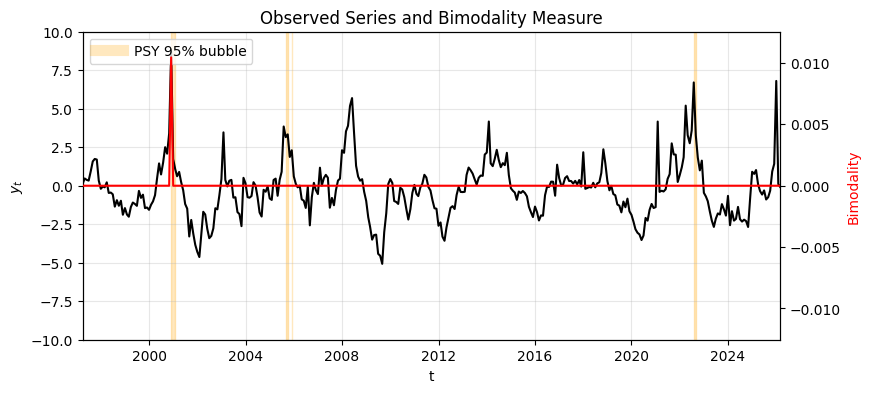

In [22]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -454.53398291016714

Estimated parameters:
phi             =     0.5412 (0.0376)
psi             =     0.3272 (0.0344)
beta_wti        =     0.0732 (0.0159)
beta_indpro     =     0.0366 (0.0097)
beta_ngas_prod  =    -0.1130 (0.0397)
beta_fedfunds   =    -0.0159 (0.0053)
beta_vix        =    -0.0703 (0.0258)
beta_epu        =     0.0506 (0.0225)
beta_gpr        =    -0.1185 (0.0424)
beta_ngas_exports =    -0.0488 (0.0226)
beta_hdd        =    -0.0544 (0.0095)
beta_cdd        =    -0.0678 (0.0201)
sigma           =     0.3929 (0.0287)

Hessian condition number:
153.73632225548747

Eigenvalues of Hessian:
[72096.32623483 22220.36317568 14624.74652001  5717.50094707
  3954.43198415  2665.11941969  2212.71228936  1548.99231152
  1230.25268325  1096.56191011   636.5726905    468.96091423
   530.28817233]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -454.533983
AIC:            935.067966
BIC:            985.146598
R^2:            

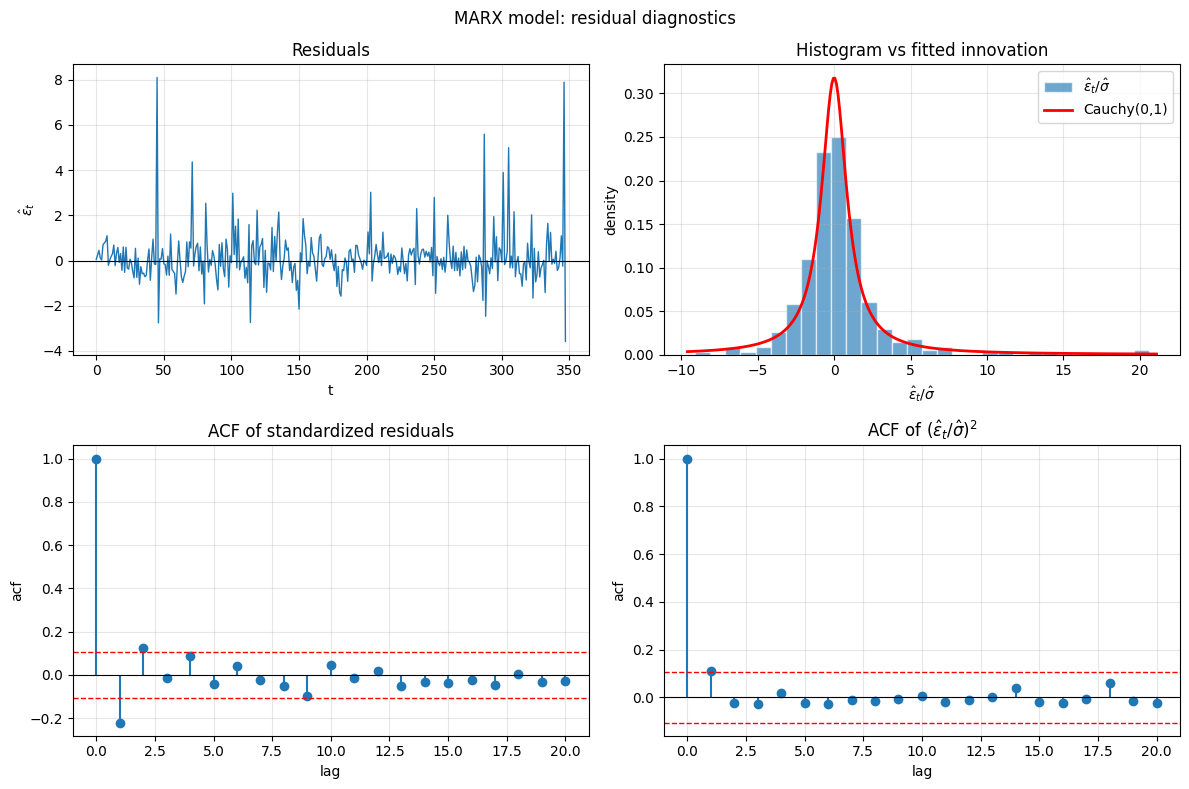

In [23]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_wti", "beta_indpro", "beta_ngas_prod", "beta_fedfunds", "beta_vix", "beta_epu", "beta_gpr", "beta_ngas_exports", "beta_hdd", "beta_cdd", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

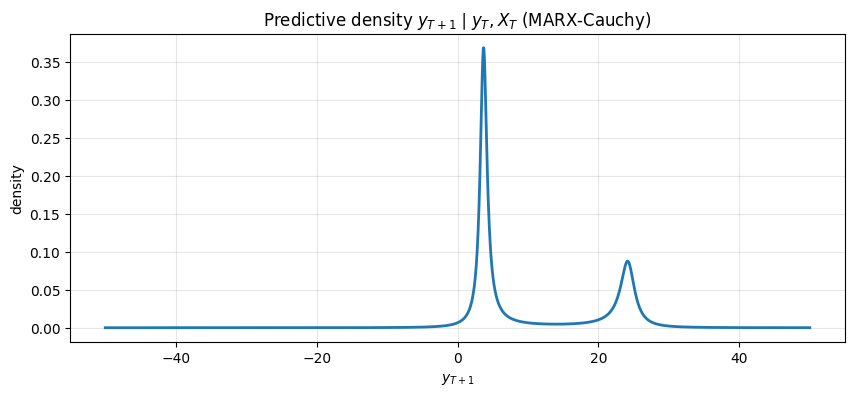

In [24]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

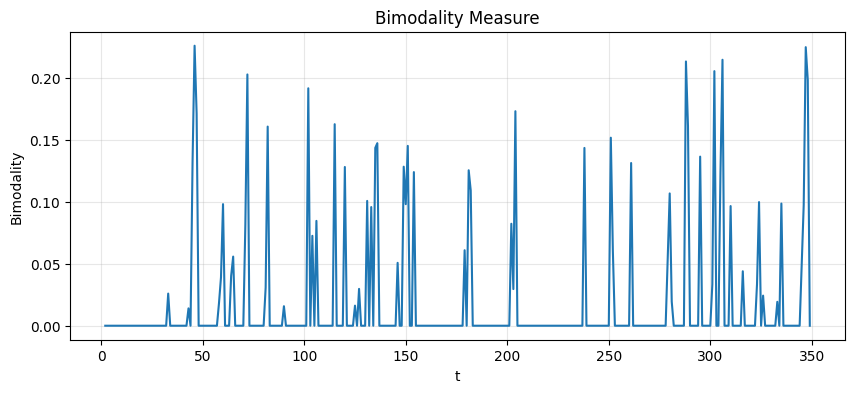

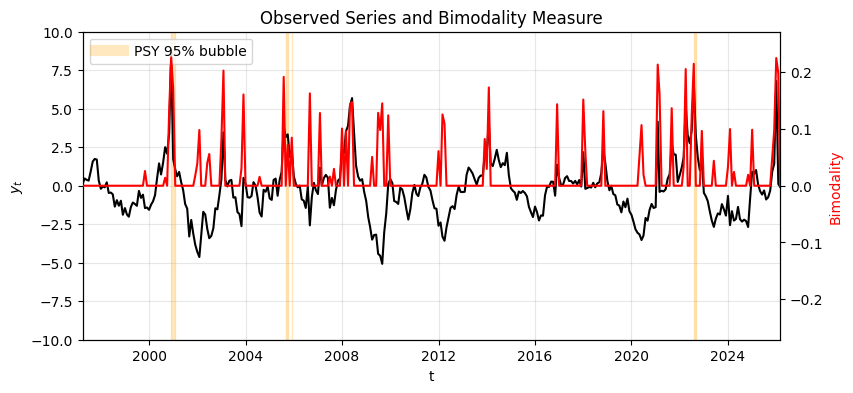

In [25]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


### Bimodality/ Predictive Density changes for different X values

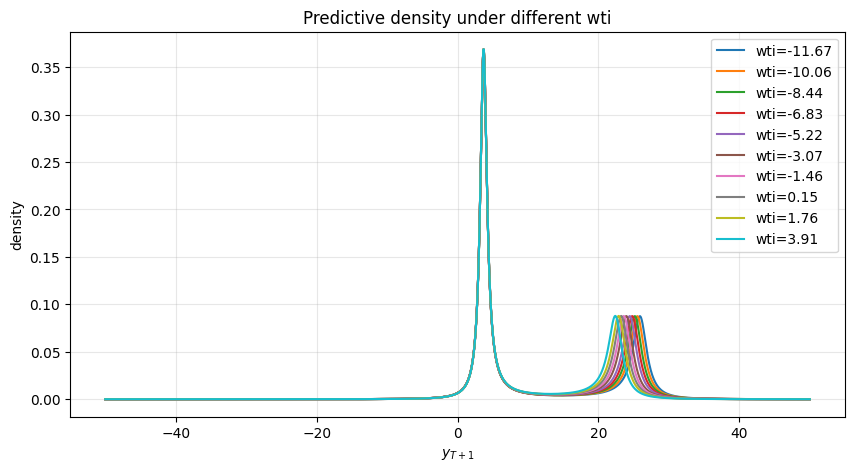

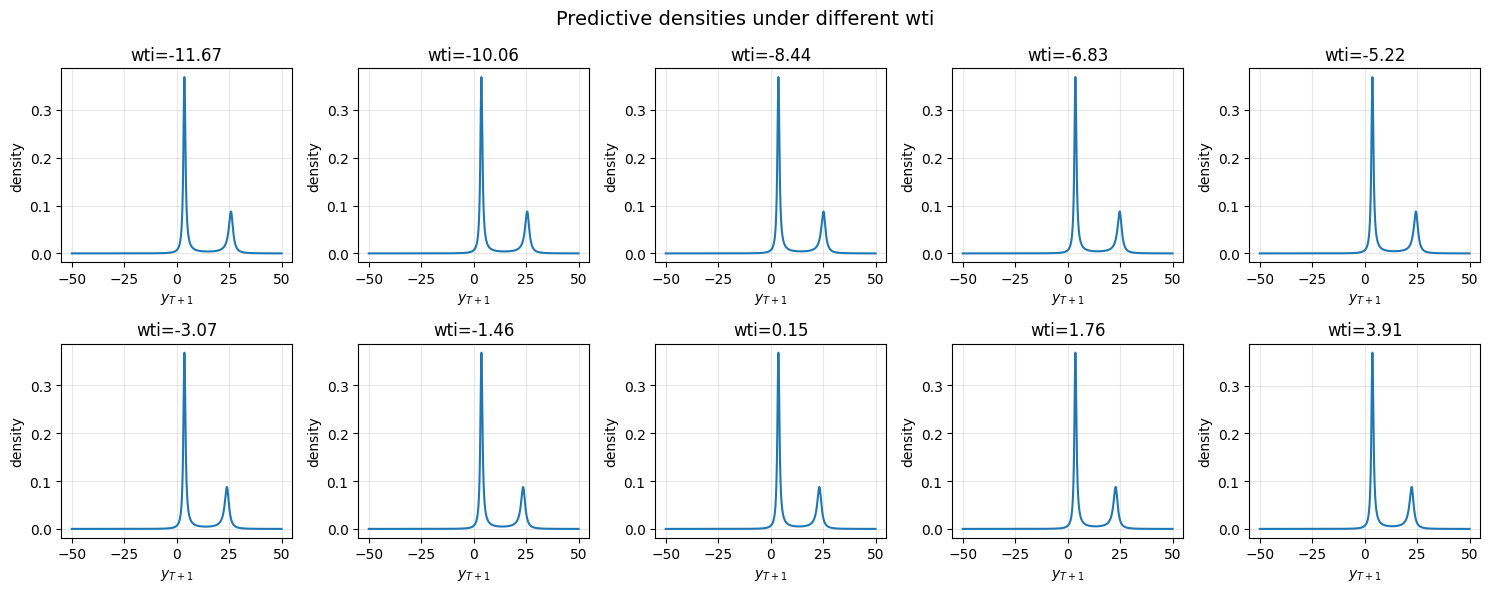

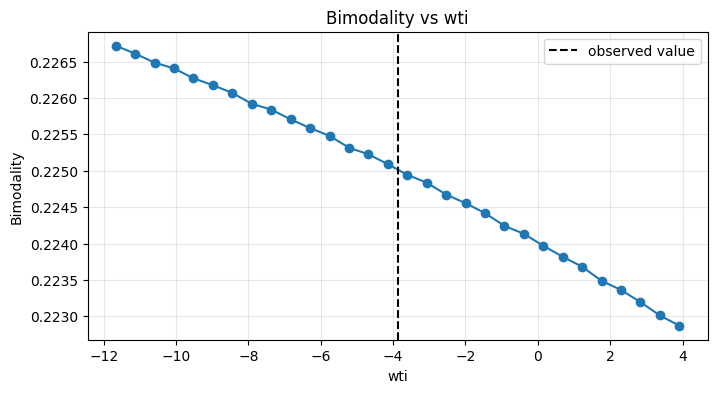

In [26]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_cauchy_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)


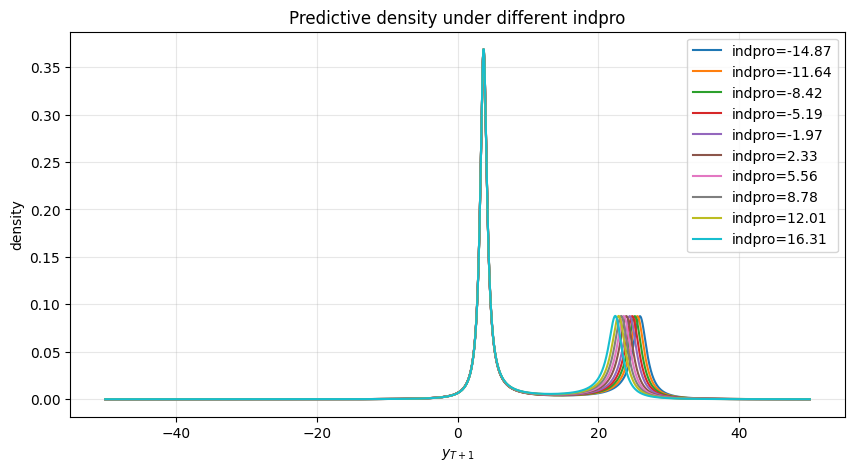

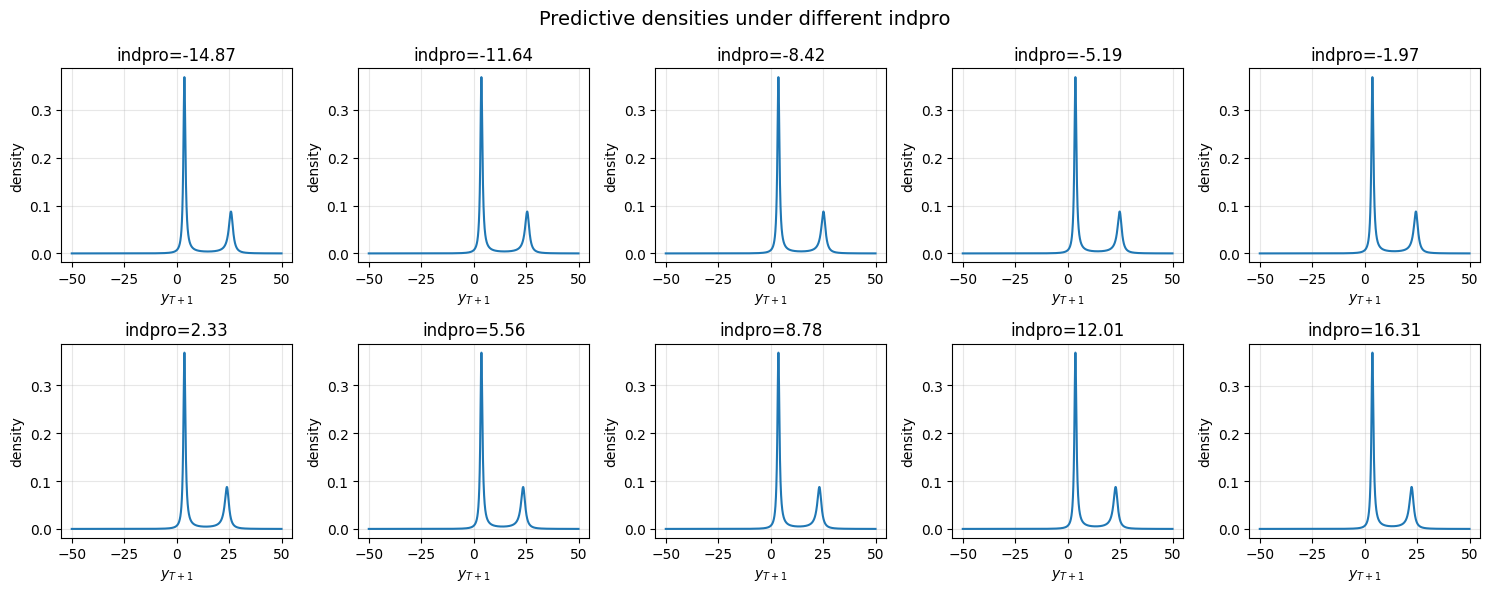

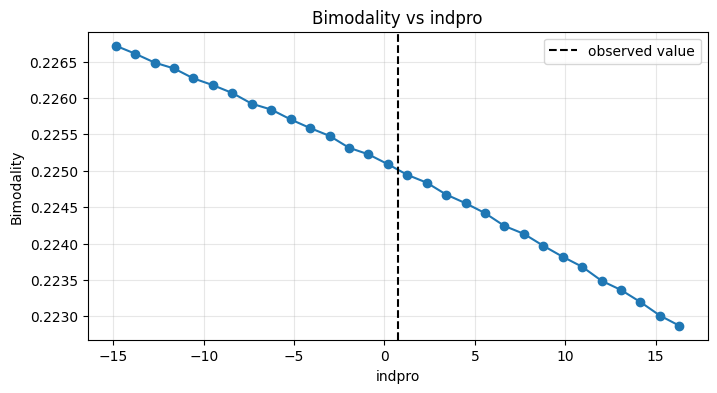

In [27]:
res = shock_analysis(
    var_idx=1,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_cauchy_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence,
)


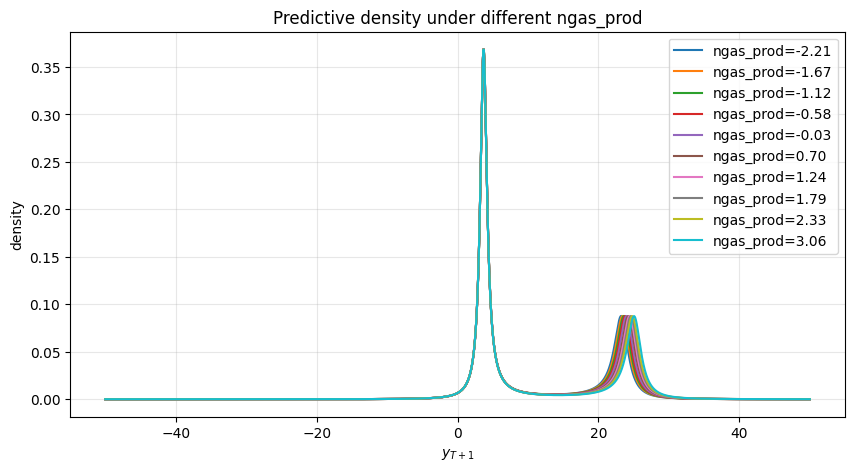

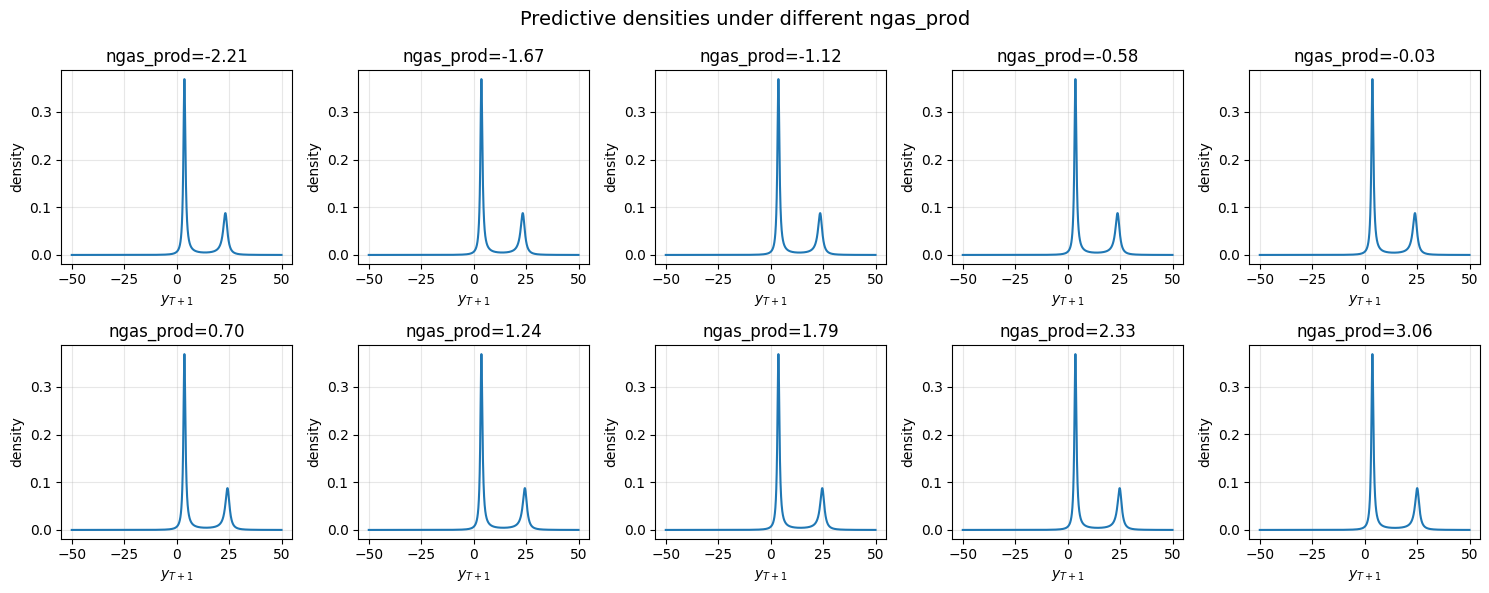

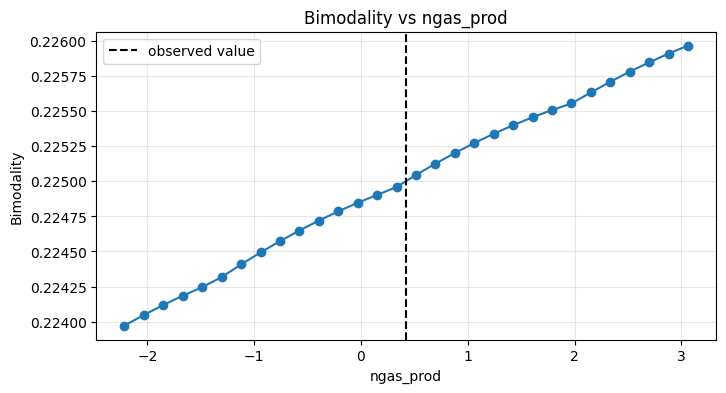

In [28]:
res = shock_analysis(
    var_idx=2,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_cauchy_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -454.83783912463275

Estimated parameters:
phi             =     0.0657 (0.0399)
psi             =     0.8339 (0.0274)
sigma           =     0.5265 (0.0410)
nu              =     2.0427 (0.2928)

Hessian condition number:
157.01091673838738

Eigenvalues of Hessian:
[1817.28911991  558.5861101  1005.76053553   11.57428514]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -454.837839
AIC:            917.675678
BIC:            933.084488
R^2:            0.616925

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 15.337355, p-value = 8.99208e-05
    lag  5: statistic = 20.558368, p-value = 0.00098137
    lag 10: statistic = 26.435777, p-value = 0.00319625
    lag 20: statistic = 30.347724, p-value = 0.0644118

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: stat

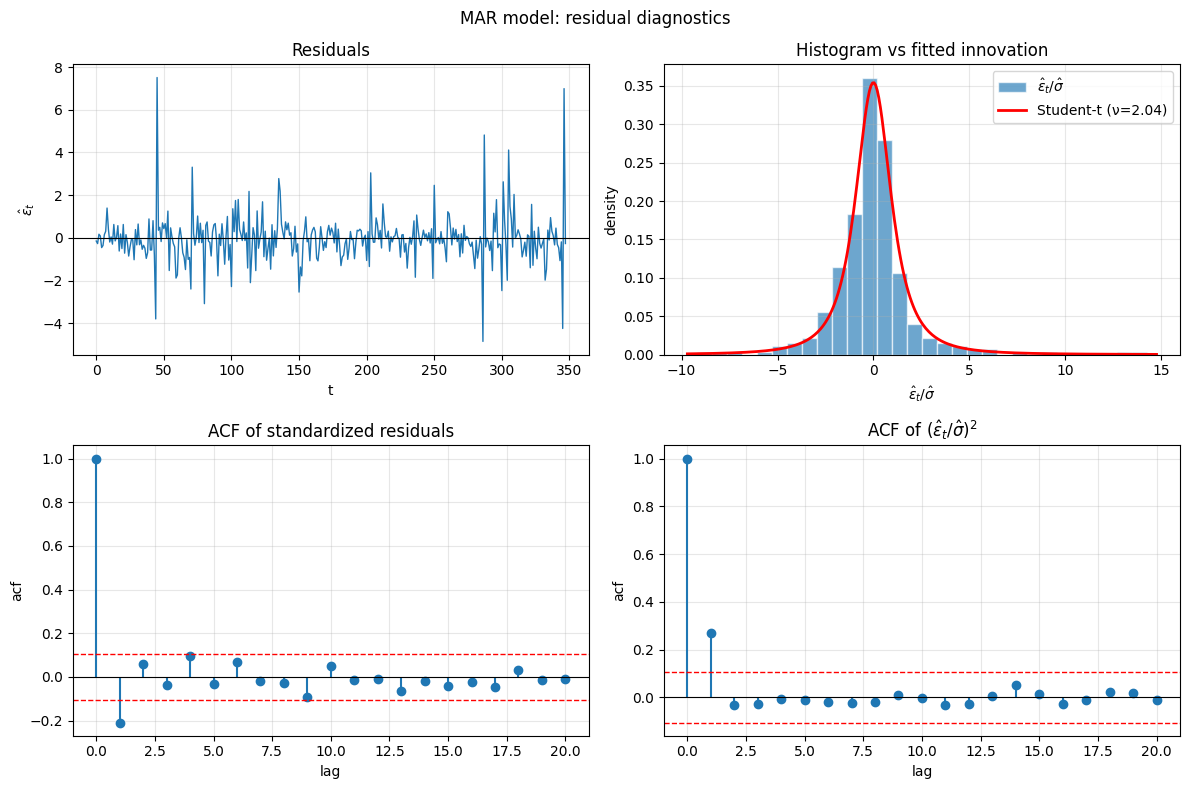

In [29]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

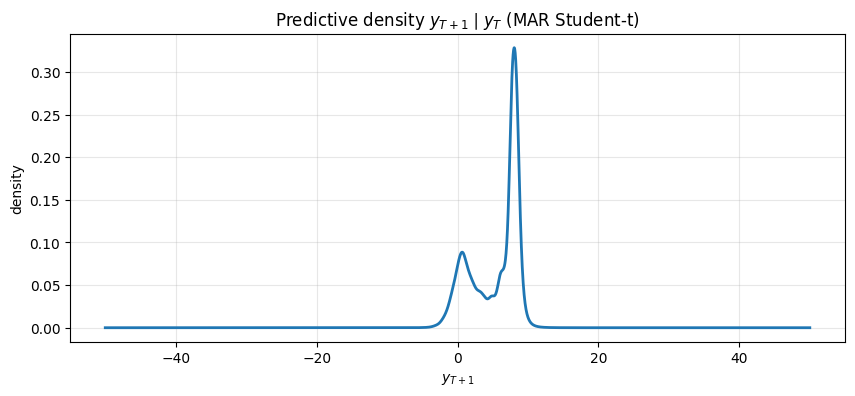

In [30]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

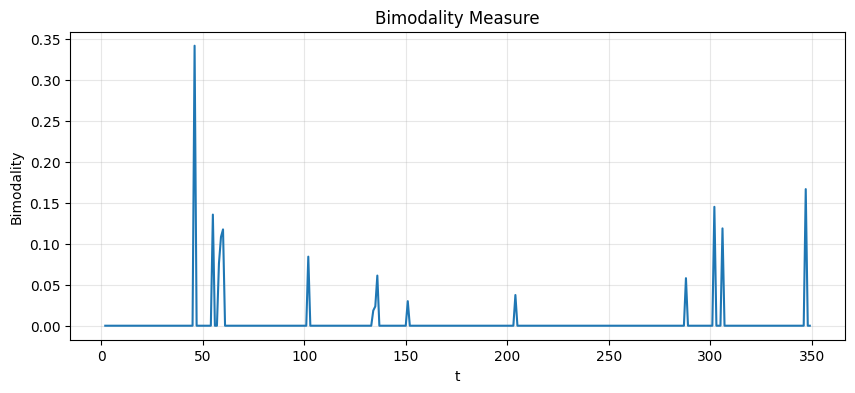

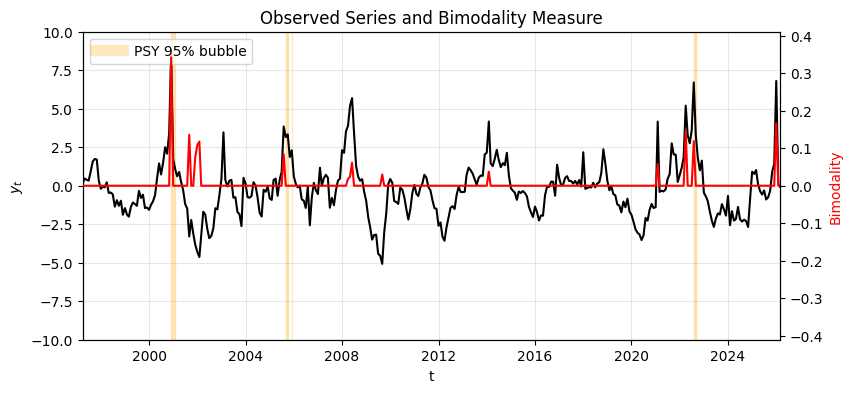

In [31]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)

----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -435.2392589426322

Estimated parameters:
phi             =     0.5441 (0.0470)
psi             =     0.3144 (0.0456)
beta_wti        =     0.0786 (0.0182)
beta_indpro     =     0.0382 (0.0110)
beta_ngas_prod  =    -0.1068 (0.0430)
beta_fedfunds   =    -0.0170 (0.0057)
beta_vix        =    -0.0640 (0.0302)
beta_epu        =     0.0396 (0.0281)
beta_gpr        =    -0.1062 (0.0412)
beta_ngas_exports =    -0.0373 (0.0220)
beta_hdd        =    -0.0422 (0.0098)
beta_cdd        =    -0.0850 (0.0224)
sigma           =     0.5281 (0.0385)
nu              =     2.2892 (0.3384)

Hessian condition number:
6647.996750305542

Eigenvalues of Hessian:
[5.77494682e+04 1.65452124e+04 1.15584876e+04 4.15368390e+03
 3.02443183e+03 2.06787324e+03 1.82010201e+03 1.32550390e+03
 8.68674736e+00 1.06821905e+03 2.75689651e+02 7.81653599e+02
 5.25532011e+02 5.81505166e+02]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -435.239259
AIC:            898

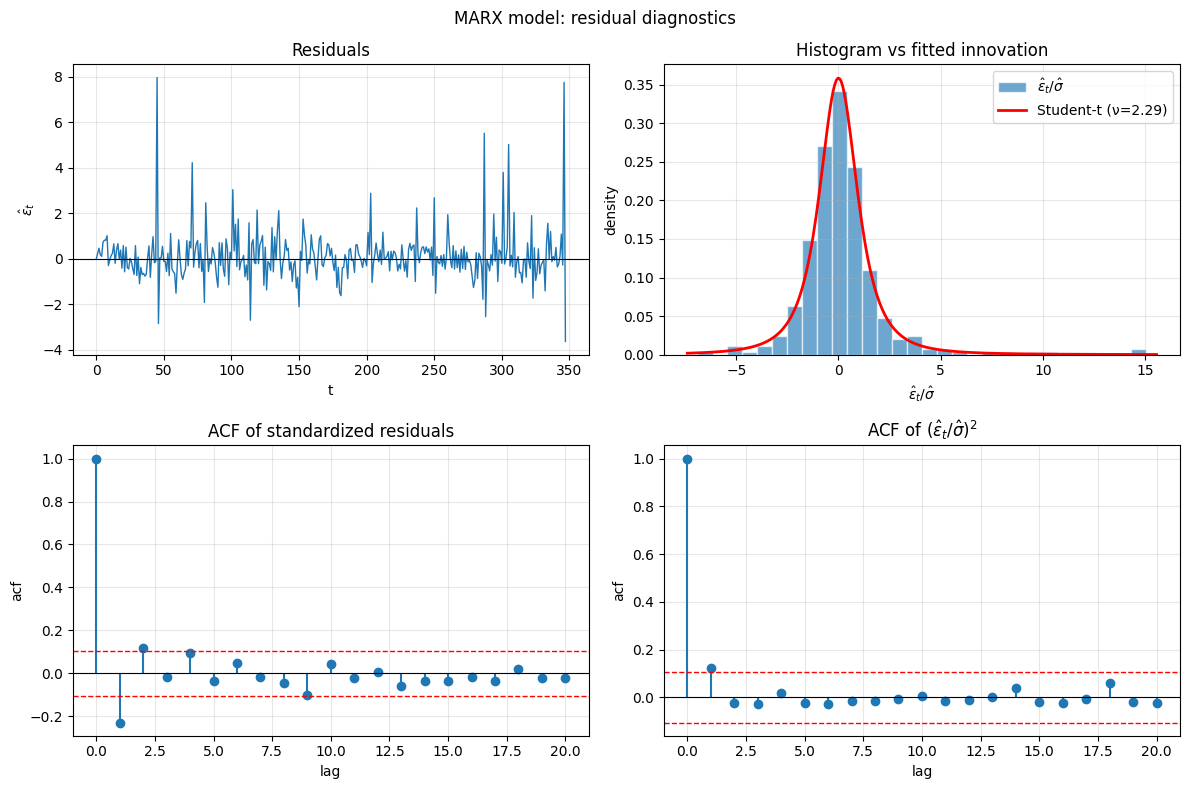

In [32]:
param_names = [ "phi", "psi", "beta_wti", "beta_indpro", "beta_ngas_prod", "beta_fedfunds", "beta_vix", "beta_epu", "beta_gpr", "beta_ngas_exports", "beta_hdd", "beta_cdd", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

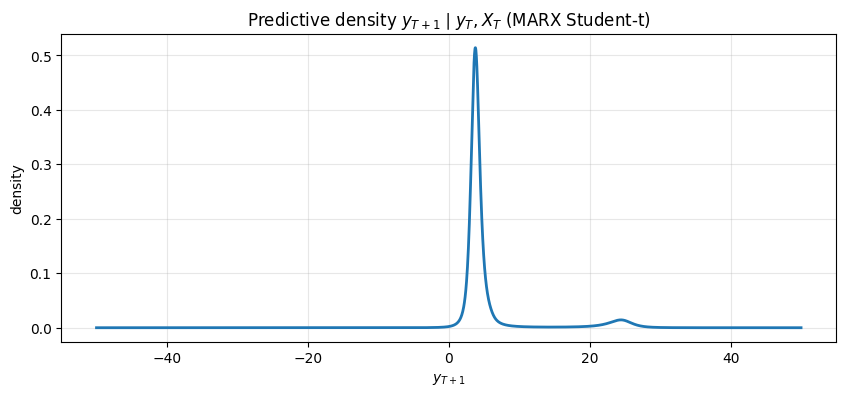

In [33]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t0,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

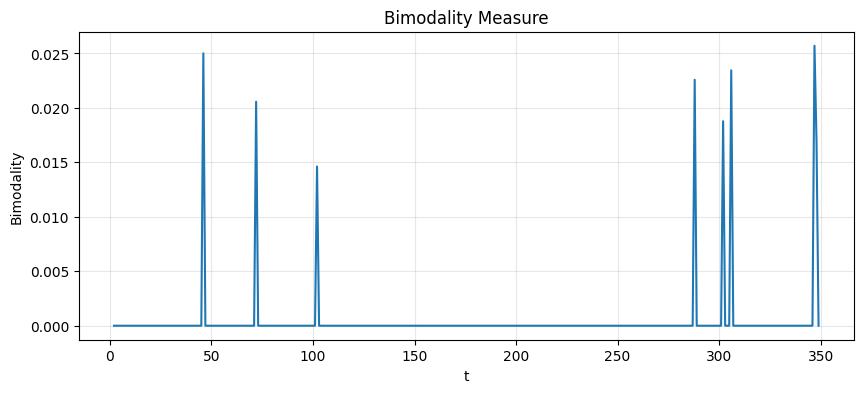

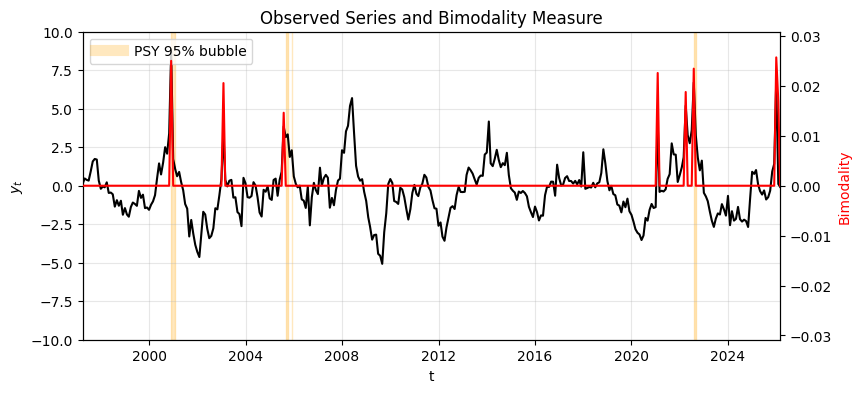

In [34]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


### Bimodality/ Predictive Density changes for different X values

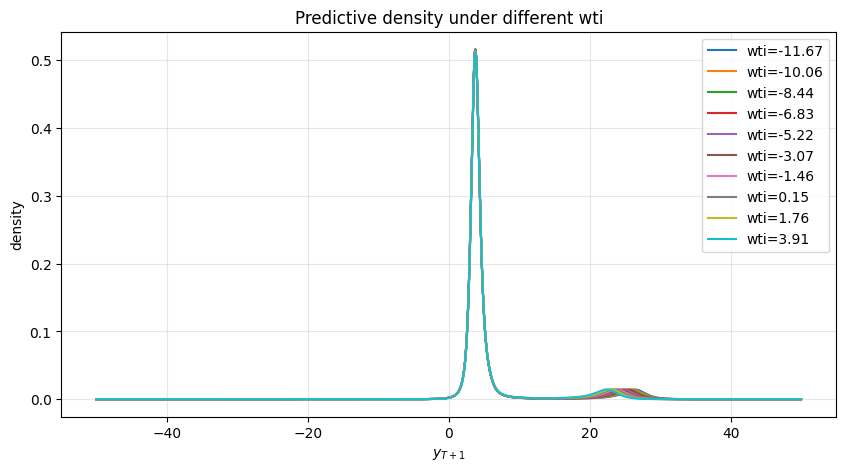

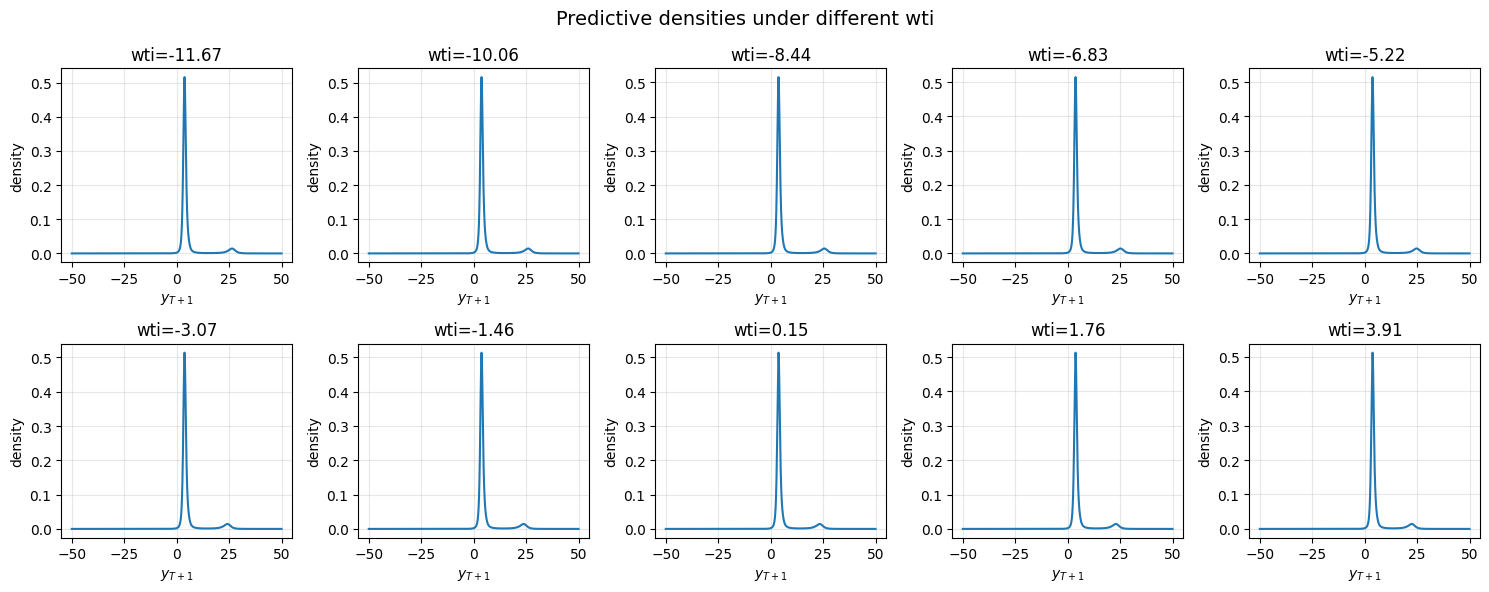

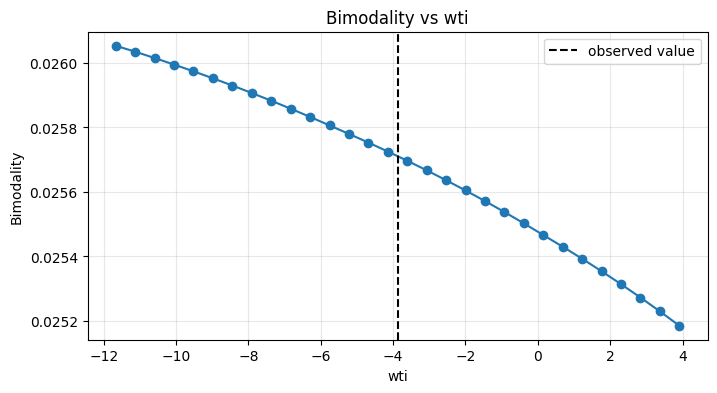

In [35]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)


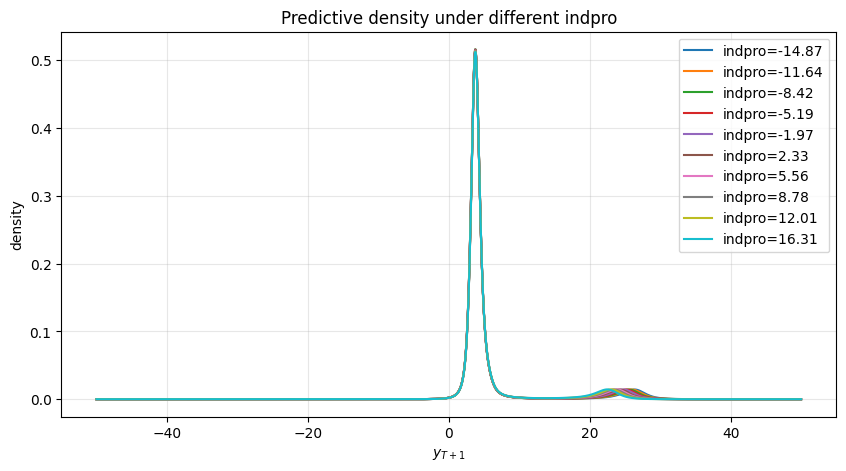

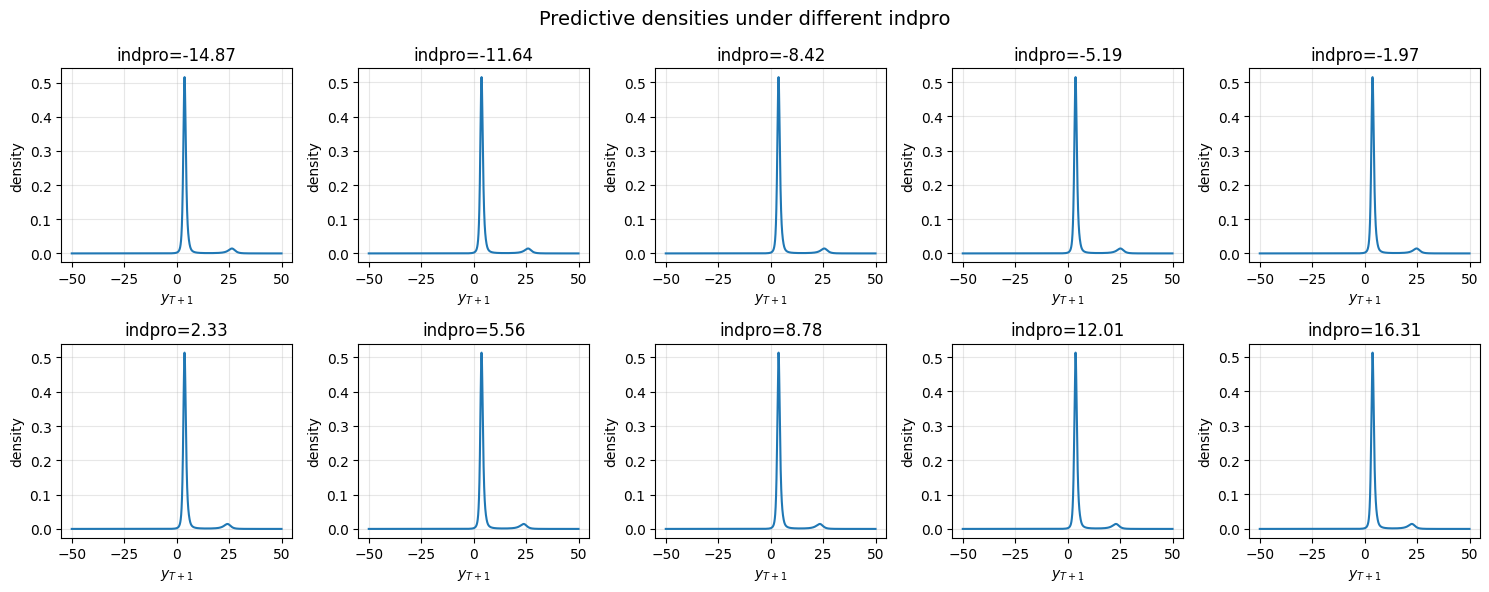

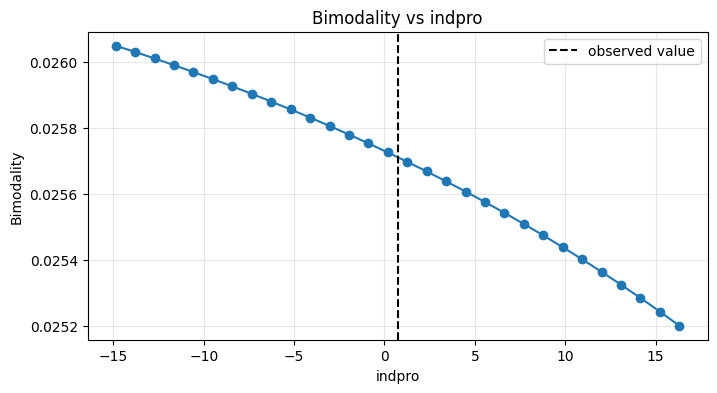

In [36]:
res = shock_analysis(
    var_idx=1,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)


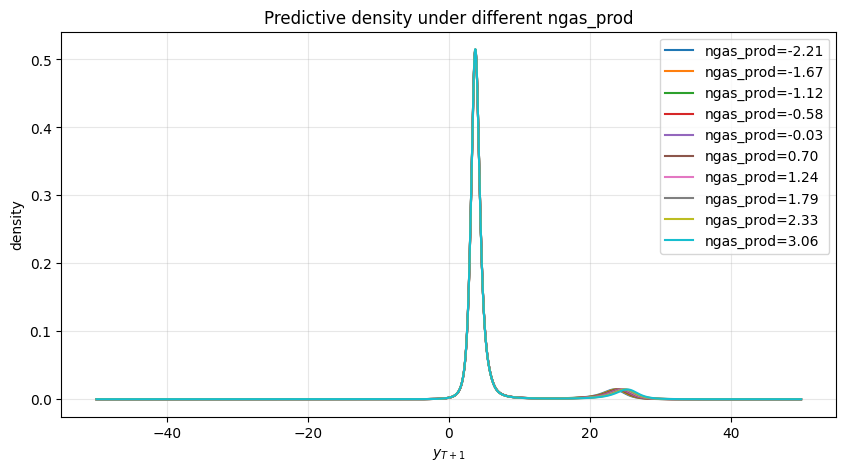

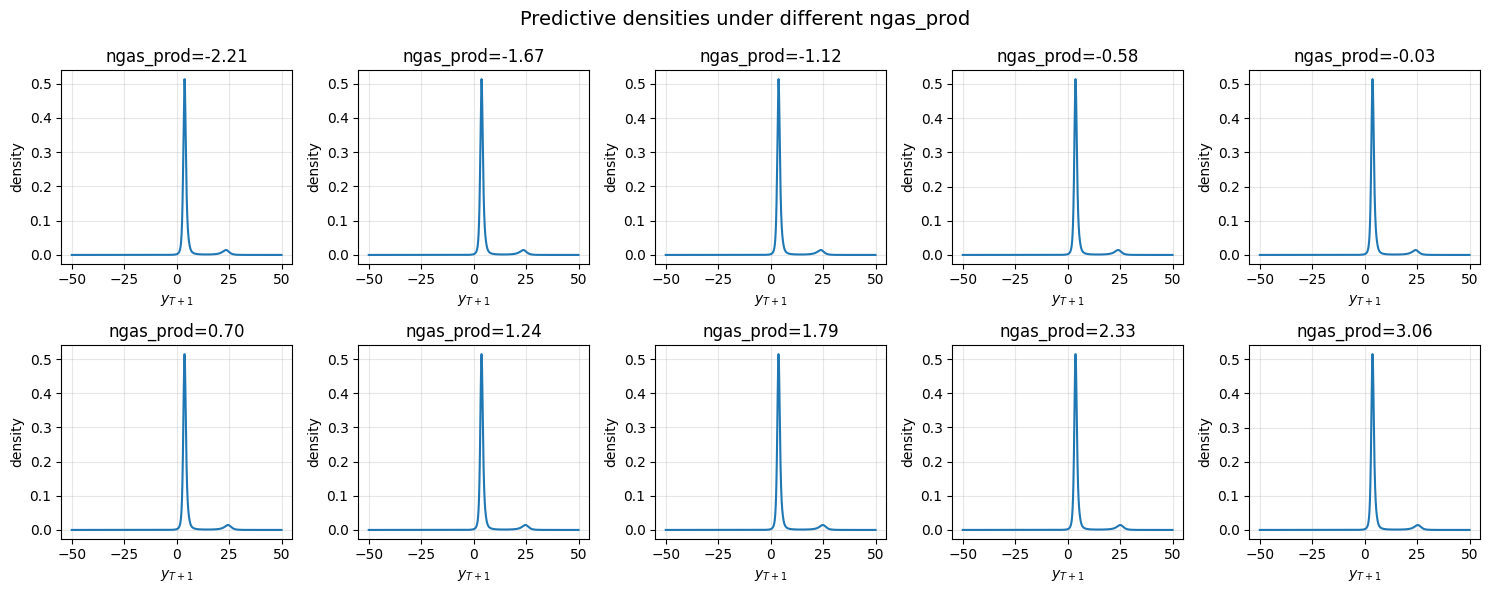

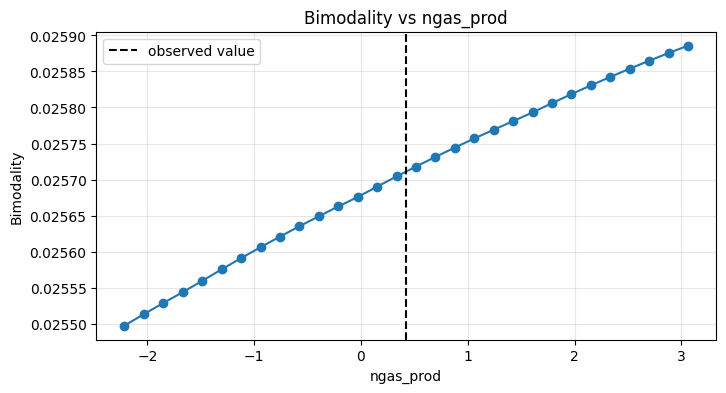

In [37]:
res = shock_analysis(
    var_idx=2,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    t_last=t0,
    prominence_factor=prominence
)
